In [80]:
import pandas as pd
import numpy as np

In [81]:
data='https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
df=pd.read_csv(data)

In [82]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [83]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [84]:
numerical=['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']
categorical=['lead_source', 'industry', 'employment_status', 'location']

In [85]:
for c in categorical:
    df[c]=df[c].fillna('NA')
for n in numerical:
    df[n]=df[n].fillna(0.0)

In [86]:
from sklearn.model_selection import train_test_split

In [87]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [88]:
y_full_train=df_full_train.converted.values
y_test=df_test.converted.values
y_train=df_train.converted.values
y_val=df_val.converted.values
del df_full_train['converted']
del df_test['converted']
del df_train['converted']
del df_val['converted']

In [89]:
from sklearn.metrics import roc_auc_score
for n in numerical:
    auc=roc_auc_score(y_train, df_train[n])
    if auc<0.5:
        auc=roc_auc_score(y_train, -df_train[n])
    print(n, auc)

annual_income 0.6081977776250831
number_of_courses_viewed 0.7229894623989618
interaction_count 0.7649203047563227
lead_score 0.7882254810906102


In [90]:
dicts=df[categorical+numerical].to_dict(orient='records')

In [91]:
from sklearn.feature_extraction import DictVectorizer
dv=DictVectorizer(sparse=False)
train_dict=df_train[categorical+numerical].to_dict(orient='records')
X_train=dv.fit_transform(train_dict)

val_dict=df_val[categorical+numerical].to_dict(orient='records')
X_val=dv.transform(val_dict)

In [92]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [93]:
y_pred=model.predict_proba(X_val)[:,1]
roc_auc_score(y_val, y_pred)

0.7318222288173319

In [ ]:
scores = {}
F1 = {}
pr_dict = {}

actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

for t in np.arange(0, 1, 0.01):
    t_key = round(t, 2)  
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0

    pr_dict[t_key] = precision
    scores[t_key] = abs(precision - recall)
    
    f1_denom = precision + recall
    F1[t_key] = (2 * precision * recall / f1_denom) if f1_denom > 0 else 0.0

valid_scores = {t: score for t, score in scores.items() if pr_dict[t] > 0}

print(min(valid_scores, key=valid_scores.get))  
print(max(F1, key=F1.get))                      

0.63
0.41


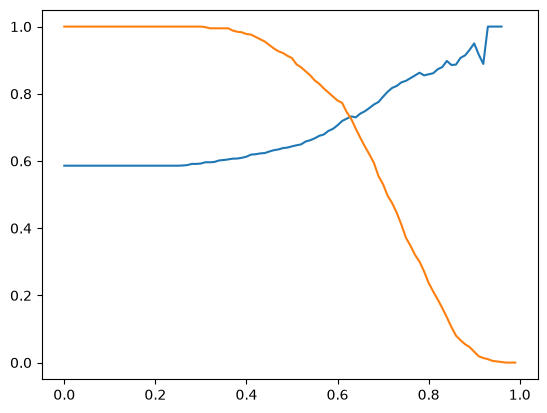

In [95]:
import matplotlib.pyplot as plt
plt.plot(np.arange(0, 1, 0.01), pr)
plt.plot(np.arange(0, 1, 0.01), rec)

In [96]:
from sklearn.model_selection import KFold

kfold=KFold(n_splits=5, shuffle=True, random_state=1)

In [97]:
def train(df_train, y_train, C=1.0):
    dicts=df_train[categorical+numerical].to_dict(orient='records')

    dv=DictVectorizer(sparse=False)
    X_train=dv.fit_transform(dicts)
    model=LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train, y_train)

    return dv, model

In [98]:
def predict(df, dv, model):
    dicts=df[categorical+numerical].to_dict(orient='records')

    X=dv.transform(dicts)
    y_pred=model.predict_proba(X)[:, 1]
    return y_pred

In [99]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)

In [100]:
scores=[]

for train_idx, val_idx in kfold.split(df_full_train):
    df_train=df_full_train.iloc[train_idx]
    df_val=df_full_train.iloc[val_idx]

    y_train=df_train.converted.values
    y_val=df_val.converted.values

    dv, model=train(df_train, y_train)
    y_pred=predict(df_val, dv, model)

    auc=roc_auc_score(y_val, y_pred)
    scores.append(auc)

np.std(scores)

np.float64(0.006853233151022138)

In [101]:
for c in [0.000001, 0.001, 1]:
    kfold=KFold(n_splits=5, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train=df_full_train.iloc[train_idx]
        df_val=df_full_train.iloc[val_idx]
        
        y_train=df_train.converted.values
        y_val=df_val.converted.values
        
        dv, model=train(df_train, y_train, C=c)
        y_pred=predict(df_val, dv, model)
        
        auc=roc_auc_score(y_val, y_pred)
        scores.append(auc)
    print('C=%s %.3f +- %.3f' % (c, np.mean(scores), np.std(scores)))
        
        

C=1e-06 0.732 +- 0.007
C=0.001 0.732 +- 0.007
C=1 0.732 +- 0.007
